In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw5.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 5: Airbnb regression 
### Associated lectures: All material till Chapter 13 

## Table of contents
0. [Submission instructions](#si)
1. [Understanding the problem](#1)
2. [Data splitting](#2)
3. [EDA](#3)
4. (Challenging) [Feature engineering](#4)
5. [Preprocessing and transformations](#5) 
6. [Baseline model](#6)
7. [Linear models](#7)
8. [Different models](#8)
9. (Challenging) [Feature selection](#9)
10. [Hyperparameter optimization](#10)
11. [Interpretation and feature importances](#11) 
12. [Results on the test set](#12)
13. [Summary of the results](#13)
14. (Challenging) [Your takeaway from the course](#15)

<div class="alert alert-info">

## Instructions
rubric={points}

You will earn points for following these instructions and successfully submitting your work in PrairieLearn.

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.

- The maximum group size is 2.
- Use group work as an opportunity to collaborate and learn new things from each other.
- Be respectful to each other and make sure you understand all the concepts in the assignment well.
- It is your responsibility to make sure your PrairieLearn group is set up correctly and that the assignment is submitted before the deadline.

### General submission instructions

- Please read the [Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2026W1/syllabus/#use-of-generative-ai-genai) before starting the homework assignment.
- **Run all cells before submitting:** Go to `Kernel -> Restart Kernel and Clear All Outputs`, then select `Run -> Run All Cells`. This ensures your notebook runs cleanly from start to finish without errors.
- **Save your work in JupyterLab:** Make sure `hw5.ipynb` is saved.
- **Choose one HW5 option:** HW5 has two dataset options in PrairieLearn. You are currently in the Airbnb regression option. Open and submit exactly one notebook, and do not submit both.
- **Check your saved submission in PrairieLearn:** Return to the PrairieLearn question page and click **Save only** to capture your notebook and review the preview. When you are ready to submit for grading, click **Save & Grade**.
- **Follow course submission guidelines:** Review the CPSC 330 homework instructions for detailed guidance on completing and submitting assignments.

</div>


## Imports

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

<!-- BEGIN QUESTION -->



In [2]:
# Core Data Analysis & Visualization (EDA)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting & Cross-Validation
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, cross_validate

# Preprocessing, Transformations & Pipelines
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline

# Feature Selection
from sklearn.feature_selection import SelectPercentile, RFE, RFECV, SelectFromModel

# Baseline Models
from sklearn.dummy import DummyClassifier, DummyRegressor

# Linear Models
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso

# Tree & Ensemble Models
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

# Model Evaluation Metrics & Interpretation
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error, r2_score


<!-- END QUESTION -->

## Introduction <a name="in"></a>

In this homework you will be working on an open-ended mini-project, where you will put all the different things you have learned so far together to solve an interesting problem.

A few notes and tips when you work on this mini-project: 

#### Tips
1. This mini-project is open-ended, and while working on it, there might be some situations where you'll have to use your own judgment and make your own decisions (as you would be doing when you work as a data scientist). Make sure you explain your decisions whenever necessary. 
2. **Do not include everything you ever tried in your submission** -- it's fine just to have your final code. That said, your code should be reproducible and well-documented. For example, if you chose your hyperparameters based on some hyperparameter optimization experiment, you should leave in the code for that experiment so that someone else could re-run it and obtain the same hyperparameters, rather than mysteriously just setting the hyperparameters to some (carefully chosen) values in your code. 
3. If you realize that you are repeating a lot of code try to organize it in functions. Clear presentation of your code, experiments, and results is the key to be successful in this lab. You may use code from lecture notes or previous lab solutions with appropriate attributions. 

#### Assessment
We plan to grade fairly and leniently. We don't have some secret target score that you need to achieve to get a good grade. **You'll be assessed on demonstration of mastery of course topics, clear presentation, and the quality of your analysis and results.** For example, if you just have a bunch of code and no text or figures, that's not good. If you do a bunch of sane things and get a lower accuracy than your friend, don't sweat it.


#### A final note
Finally, this style of this "project" question is different from other assignments. It'll be up to you to decide when you're "done" -- in fact, this is one of the hardest parts of real projects. But please don't spend WAY too much time on this... perhaps "a few hours" (15-20 hours???) is a good guideline for this project . Of course if you're having fun you're welcome to spend as much time as you want! But, if so, try not to do it out of perfectionism or getting the best possible grade. Do it because you're learning and enjoying it. Students from the past cohorts have found such kind of labs useful and fun and we hope you enjoy it as well. 

<br><br>

<!-- BEGIN QUESTION -->

<!-- BEGIN QUESTION -->

## 1. Pick your problem and explain the prediction problem
<hr>
rubric={points:3}

This version of Homework 5 uses the [New York City Airbnb Open Data dataset](https://www.kaggle.com/dgomonov/new-york-city-airbnb-open-data). You will work on a regression problem where the goal is to predict `reviews_per_month`, as a proxy for listing popularity. Airbnb could use this sort of model to predict how popular future listings might be before they are posted, perhaps to help guide hosts in creating more appealing listings. In reality they might instead use something like vacancy rate or average rating as their target, but we do not have that available here.

> Note there is an updated version of this dataset with more features available [here](http://insideairbnb.com/). The features we are using are in `listings.csv.gz` for the New York City dataset. You will also see some other files like `reviews.csv.gz`. For your own interest you may want to explore the expanded dataset and try your analysis there. However, please submit your results on the dataset obtained from Kaggle.

<div class="alert alert-info">
    
**Your tasks:**

1. Spend some time understanding the problem and what each feature means. You can find an explanation of the features [here](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit).
2. Download the dataset and load it into a pandas DataFrame.
3. Write a few sentences summarizing your initial thoughts about the problem and the dataset.
   
</div>


<div class="alert alert-warning">
    
Solution_1
    
</div>

_Points:_ 3

The dataset contains information about each listing, including its location, room type, price, minimum nights required, number of reviews, and availability throughout the year. There will likely be many unused features that intuitively would not factor into the the quality of the posting or the number of review that the posting would get each month, such as host_id or the id of the example. I expect that factors such as price, location, and room type may influence a listing's popularity. However, the data contains missing values in reviews_per_month, particularly for listings with no reviews, so these will need to be handled before building the model. The most intuitive way that we can handle this is to simply replace all the NaN values with 0. One challenge is that popularity may depend on other factors not included in the dataset that would need to be manipulated in some way, such as neighbourhood group and neighbourhood. 

In [5]:
nyc = pd.read_csv("data/AB_NYC_2019.csv")
nyc.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
print(nyc.columns)

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')


In [9]:
nyc['room_type'].unique()

<ArrowStringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 2. Data splitting <a name="2"></a>
<hr>
rubric={points:2}

**Your tasks:**

1. Split the data into train (70%) and test (30%) portions with `random_state=123`.

> If your computer cannot handle training on 70% training data, make the test split bigger.  

<div class="alert alert-warning">
    
Solution_2
    
</div>

_Points:_ 2

In [6]:
RANDOM_STATE = 123

# Separate the target from the examples
X = nyc.drop(columns=['reviews_per_month'])
y = nyc['reviews_per_month'].fillna(0) # Fill the missing values with 0, y cannot have NaNs

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 3. EDA <a name="3"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Perform exploratory data analysis on the train set.
2. Include at least two summary statistics and two visualizations that you find useful, and accompany each one with a sentence explaining it.
3. Summarize your initial observations about the data. 
4. Pick appropriate metric/metrics for assessment. 

<div class="alert alert-warning">
    
Solution_3
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [7]:
# Combine training features and target for EDA
train_df = X_train.copy()
train_df["reviews_per_month"] = y_train

# Summary statistic 1: target variable
print("Reviews per month:")
print(train_df["reviews_per_month"].describe())
print("Median: ")
print(train_df["reviews_per_month"].median())

# Summary statistic 2: listing price
print("\nListing price:")
print(train_df["price"].describe())
print("Median: ")
print(train_df["price"].median())

# Summary statistic 3: availability_365
print("\nAvailability:")
print(train_df["availability_365"].describe())
print("Median: ")
print(train_df["availability_365"].median())

Reviews per month:
count    34226.000000
mean         1.090058
std          1.614532
min          0.000000
25%          0.040000
50%          0.370000
75%          1.570000
max         58.500000
Name: reviews_per_month, dtype: float64
Median: 
0.37

Listing price:
count    34226.000000
mean       151.528399
std        236.628392
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64
Median: 
106.0

Availability:
count    34226.000000
mean       112.526004
std        131.420031
min          0.000000
25%          0.000000
50%         45.000000
75%        225.750000
max        365.000000
Name: availability_365, dtype: float64
Median: 
45.0


The summary statistics provide useful insights into the distribution of listing popularity, price, and availability. For reviews per month, the mean is 1.09, while the median is only 0.37, suggesting that the distribution is right-skewed, with a small number of listings receiving many reviews. The maximum of 58.5 reviews per month is much higher than the 75th percentile of 1.57, indicating potential outliers. These statistics are useful for understanding the typical popularity of a listing and identifying extreme values that could affect the regression model.

For listing price, the mean is 151.53 per night, compared with a median of 106. The large standard deviation of 236.63 and maximum price of 10,000 suggest substantial variation and a right-skewed distribution. The median may therefore be more representative of a typical listing than the mean. These statistics are useful for understanding pricing differences and determining whether outliers should be investigated before modeling.

For availability, listings are available for an average of 112.53 days per year, while the median is only 45 days. The 25th percentile is zero, meaning at least 25% of listings have no available days during the year, while the 75th percentile is 225.75 days. This wide spread suggests that availability varies considerably across listings. These statistics are useful for understanding differences in host availability and investigating whether availability is associated with listing popularity.

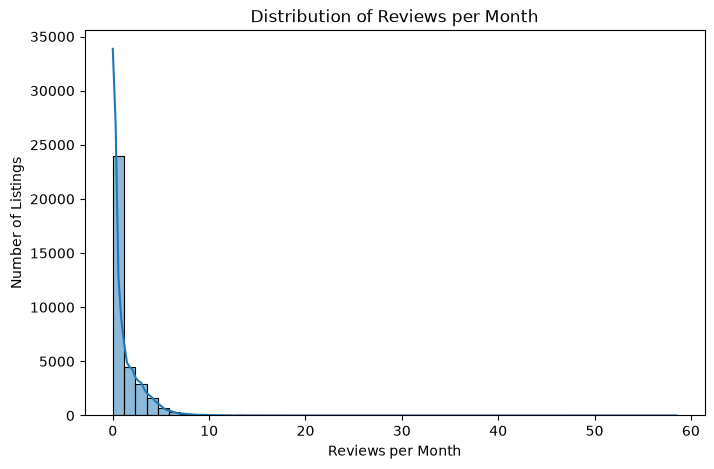

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(train_df["reviews_per_month"], bins=50, kde=True)
plt.title("Distribution of Reviews per Month")
plt.xlabel("Reviews per Month")
plt.ylabel("Number of Listings")
plt.show()

In the histogram above for the target vector, we see a right skewed distribution with a mean at about 1. The scale of this graph is incredibly large for its range because of a large outlier value at 58, which would also factor into the final predictions when this model is transformed. Due to the large amount of examples having close to 1 review, there is a chance that the final predictions of the model we make would favour lower predictions, especially with listings with average feature values. The skewed distribution and extreme values may affect model performance, so it will be important to evaluate the predictions using appropriate regression metrics such as MAE and RMSE, or it may be necessary to remove the example entirely from the training. 

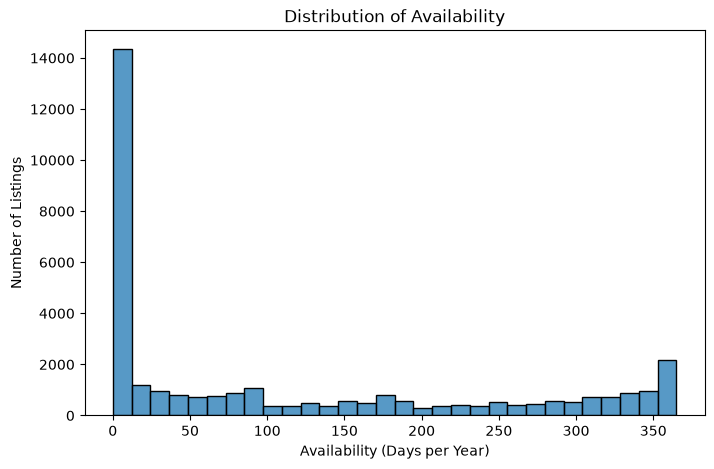

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(data=train_df, x="availability_365", bins=30)

plt.title("Distribution of Availability")
plt.xlabel("Availability (Days per Year)")
plt.ylabel("Number of Listings")
plt.show()

The plot of availability shows a heavy right skew in the distribution with a slight peak at the largest values of 365. This would make the tranformation of this column difficult as StandardScaler() relies on the assumption that the data is uniformly distributed. We saw from the sample statistics above that the mean of availability_365 is about 112, but we see that barely any of the values in the dataset actually are actually at or near that value. This is further supported by the large standard deviation value that is even larger than the mean itself, and the median of 45 that is well below the mean of 112. We should find a way to standardize in a way that would capture this features heavy skew towards the lower range of values, with a secondary spike at the max range. 

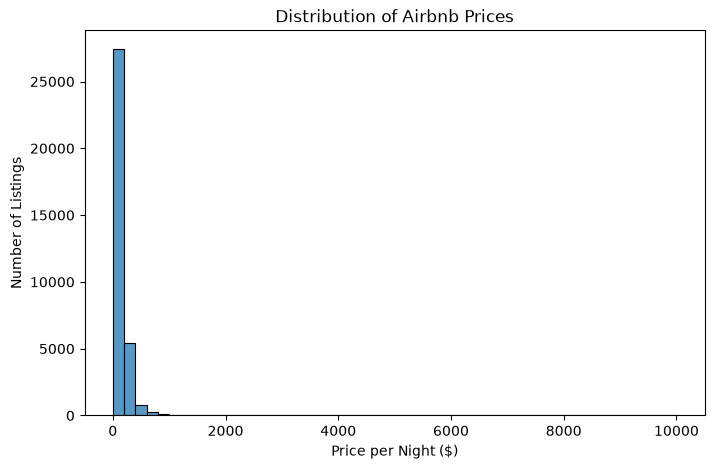

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(data=train_df, x="price", bins=50)

plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.show()

In [30]:
index = nyc.index[nyc["price"] == 10000].tolist()
print(nyc.loc[index])

             id                                             name   host_id  \
9151    7003697              Furnished room in Astoria apartment  20582832   
17692  13894339  Luxury 1 bedroom apt. -stunning Manhattan views   5143901   
29238  22436899                              1-BR Lincoln Center  72390391   

      host_name neighbourhood_group    neighbourhood  latitude  longitude  \
9151   Kathrine              Queens          Astoria  40.76810  -73.91651   
17692      Erin            Brooklyn       Greenpoint  40.73260  -73.95739   
29238    Jelena           Manhattan  Upper West Side  40.77213  -73.98665   

             room_type  price  minimum_nights  number_of_reviews last_review  \
9151      Private room  10000             100                  2  2016-02-13   
17692  Entire home/apt  10000               5                  5  2017-07-27   
29238  Entire home/apt  10000              30                  0         NaN   

       reviews_per_month  calculated_host_listings_count 

This search revealed that there were 3 separate listings with the outlier value of 10000, which will need to be accounted for before preprocessing. My initial thoughts are that if we want to make a more general model that accounts for the majority of listings, and accept the tradeoff that the model will perform much worse for these values where the values of unbounded features such as price is incredibly high, then we can simply remove all the examples where the feature value exceeds a certain threshold. Just for fun, lets see how many listings are above 3 standard deviations above the mean (~900), which turns out to be 300 or about 1% of the total dataset. This sucks but losing this data in a set of n=~30000 is not the biggest deal in the world. We can also change our loss function from least squares loss to absolute error loss to mitigate these trends. 

In [33]:
index = nyc.index[nyc["price"] > 900].tolist()
print(len(nyc.loc[index]))

353


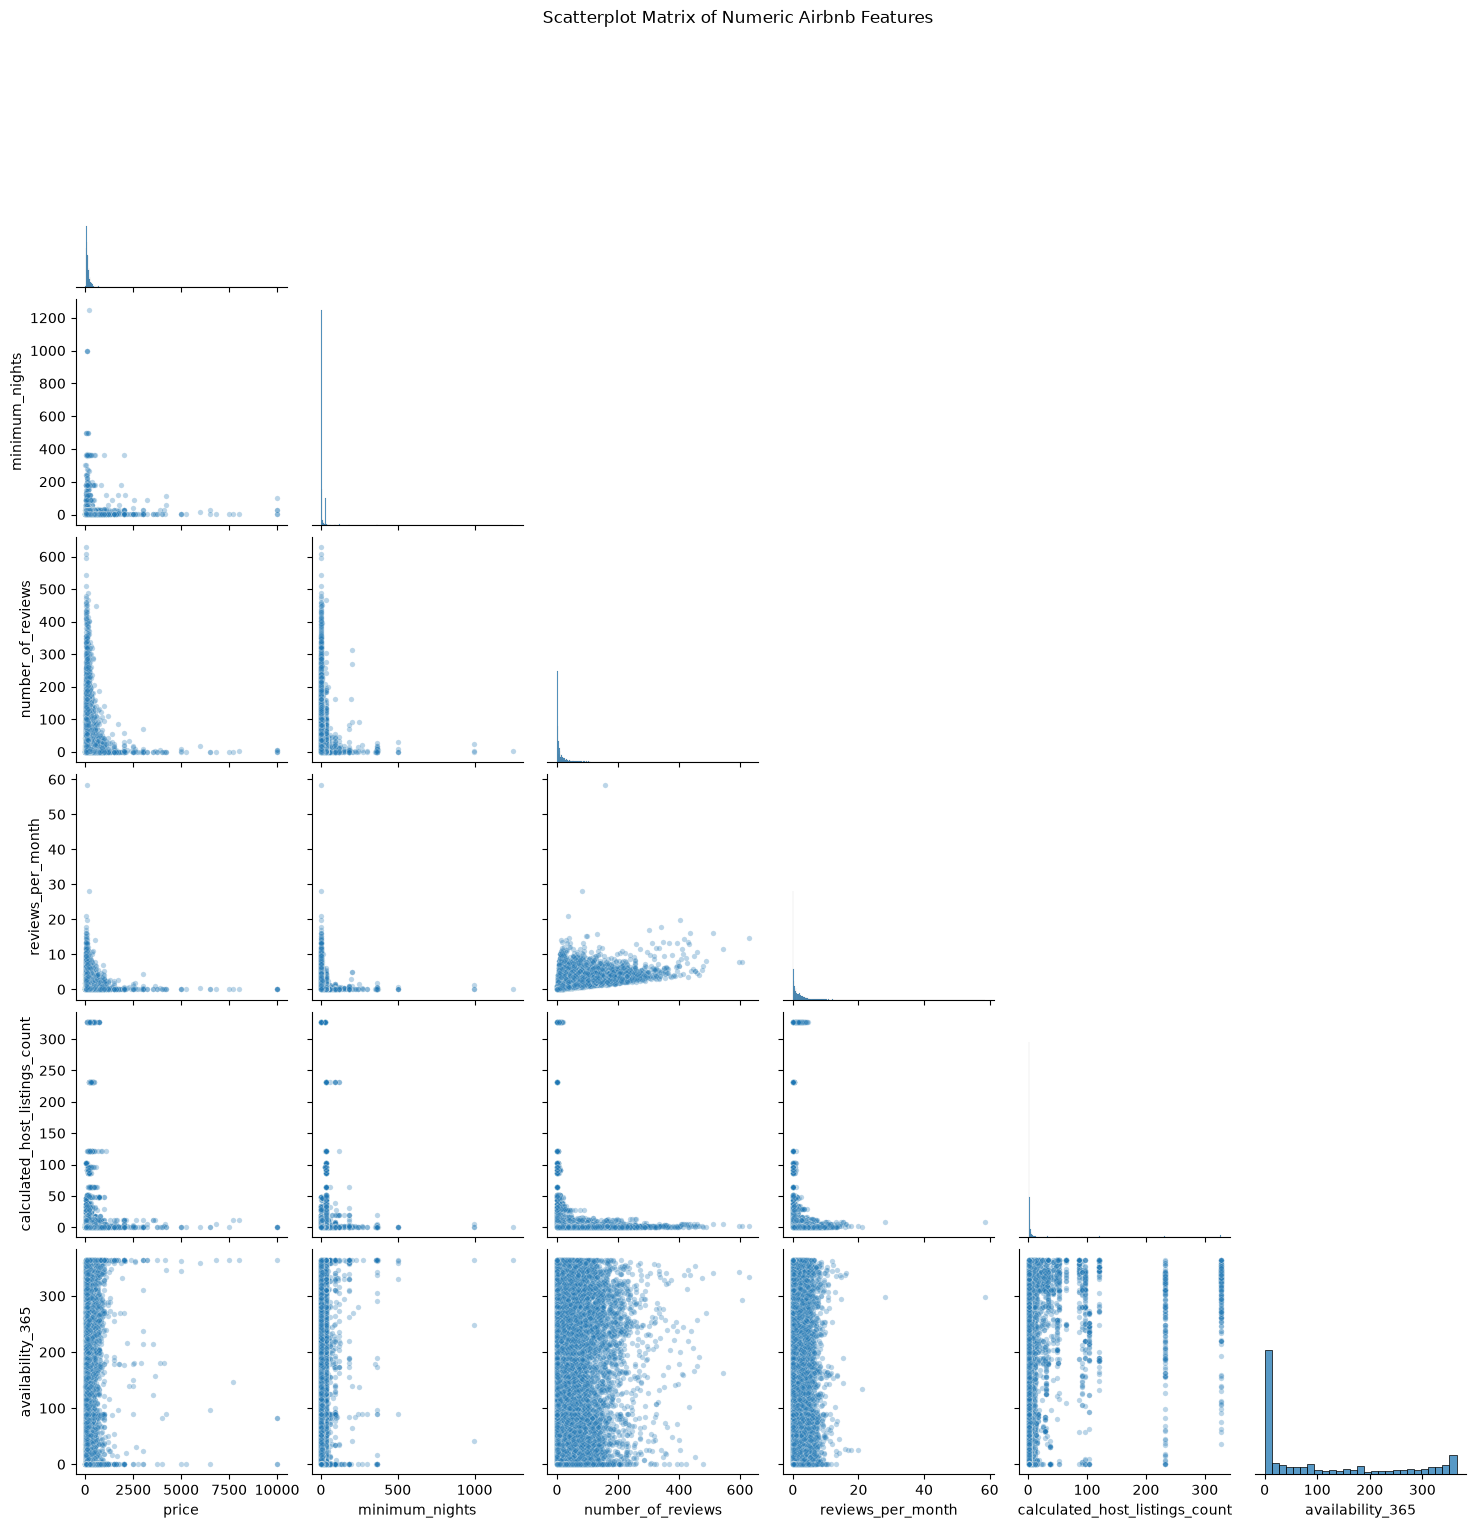

In [14]:
# Select the numeric features
numeric_features = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# Create scatterplot matrix
sns.pairplot(
    train_df[numeric_features],
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.3, "s": 15}
)

plt.suptitle("Scatterplot Matrix of Numeric Airbnb Features", y=1.02)
plt.show()

ChatGPT was used to assist in the writing of this analysis. It's quite long and a lot to type out by myself. 

The scatterplot matrix shows several interesting relationships between the numerical features in the NYC Airbnb dataset. The most noticeable patterns are the strong right-skew in several variables, the relationship between number_of_reviews and reviews_per_month, and the possible relationships between price, minimum nights, and listing popularity.
1. Relationships with the target: reviews_per_month
number_of_reviews and reviews_per_month show a generally positive association. Listings with higher total review counts tend to have a wider range of monthly review rates, and many of the listings with high monthly review rates also have relatively high total review counts. However, the relationship is not perfectly linear, and there is considerable variation. This makes sense because number_of_reviews measures reviews accumulated over time, whereas reviews_per_month measures the rate at which reviews are received. The two variables are related, but they capture different aspects of listing activity.

price and reviews_per_month do not show a clear linear relationship. Most listings are concentrated at lower prices and lower monthly review rates. Some inexpensive listings receive many reviews per month, but there are also inexpensive listings with almost no reviews. This suggests that price alone may not be enough to predict popularity, and other factors such as location, room type, and availability may be important.

minimum_nights and reviews_per_month show a concentration of observations at low values. Most listings have relatively low minimum-night requirements, and many receive few reviews per month. Listings with extremely high minimum-night requirements generally do not show high monthly review rates in this plot. This may indicate that strict minimum stays are associated with lower review activity, although the scatterplot alone cannot establish that relationship conclusively.

calculated_host_listings_count and reviews_per_month also show a concentration near the lower end. Most listings belong to hosts with relatively few listings, while a small number of hosts manage many properties. High host listing counts do not consistently correspond to high monthly review rates. Therefore, the number of listings managed by a host may be useful as a feature, but its relationship with popularity appears more complicated than a simple linear trend.

availability_365 and reviews_per_month show no strong, obvious linear pattern. Listings appear across a wide range of availability levels and monthly review rates. Some listings with high availability receive reviews frequently, while others receive very few. Availability alone therefore may not be a reliable indicator of popularity. One possible explanation is that availability measures the number of days a listing can be booked, not how frequently it is actually booked.
2. Relationships among the predictor features
Price and minimum nights
The scatterplot shows that most listings have relatively low prices and low minimum-night requirements. A small number of listings have very high prices or unusually high minimum-night requirements. There may be some concentration of high minimum-night requirements among lower-priced listings, but the extreme values make the overall relationship difficult to assess. The plot does not suggest a clear, strong linear relationship between these two features.
Price and number of reviews
Most listings with high review counts are concentrated at lower price levels. Expensive listings are relatively sparse and generally do not reach the largest review counts shown in the matrix. This could indicate that lower-priced listings attract more guests or are booked more frequently, creating more opportunities for reviews. However, this pattern may also reflect differences in location, room type, or other factors, so it should not be interpreted as evidence that price directly causes review activity.
Number of reviews and availability
There is substantial variation in total reviews across availability levels. Listings with high availability can have either many or few reviews, and listings with low availability also show a wide range of review counts. This suggests that availability and total reviews do not have a simple linear relationship. A listing may be highly available because it is rarely booked, or it may have many available days despite receiving frequent bookings.
Host listing count and other features
calculated_host_listings_count is strongly concentrated near low values, with a few hosts managing many listings. These high-count observations appear as isolated points in several panels. There is no obvious strong linear relationship between host listing count and price, minimum nights, or availability. However, hosts with many listings may operate differently from hosts with a single property, so this feature could still help a predictive model capture differences in hosting behavior.
3. Distribution patterns and outliers
The diagonal histograms reveal that several numeric features are heavily right-skewed:
- price: Most listings are concentrated at lower prices, with a small number of extremely expensive listings, including a maximum of $10,000.
- minimum_nights: Most listings have relatively low minimum-night requirements, while a few have extremely high values.
- number_of_reviews: Most listings have relatively few reviews, with a small number accumulating several hundred.
- reviews_per_month: Most listings have low monthly review rates, while a few have exceptionally high values.
- calculated_host_listings_count: Most hosts manage relatively few listings, while a small number manage many.
- availability_365: Availability has a more varied distribution, with noticeable concentrations near zero and near 365 days.
These skewed distributions are important because extreme observations can dominate the visual scale and may influence some regression models more than others. Transformations, robust evaluation metrics, or closer investigation of outliers may be worth considering later, depending on the modeling approach.
4. What this means for the regression problem
The scatterplot matrix suggests that no single numeric feature has an obviously strong, simple linear relationship with reviews_per_month, although number_of_reviews appears positively associated with it. Combining several features may therefore be more useful than relying on just one predictor.

One important modeling consideration is that number_of_reviews may be a form of information leakage for the intended use case. If Airbnb wants to predict the popularity of a listing before it is posted, its total number of reviews would not yet be available. It is reasonable to examine this feature during EDA, but it should likely be excluded from a model intended to predict popularity for brand-new listings.

Overall, the matrix suggests that listing popularity is likely influenced by multiple factors, while the heavily skewed distributions and extreme values may complicate model fitting. It would be useful to compare a baseline regression model against a more flexible model and evaluate performance using MAE and RMSE.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 4. Feature engineering <a name="4"></a>
<hr>
rubric={points:1}

**Your tasks:**

1. Carry out feature engineering. In other words, extract new features relevant for the problem and work with your new feature set in the following exercises. You may have to go back and forth between feature engineering and preprocessing. 

<div class="alert alert-warning">
    
Solution_4
    
</div>

_Points:_ 1

In [10]:
def add_features(X):
    X = X.copy()
    # Interaction feature: price per minimum stay
    X["price_per_minimum_stay"] = X["price"] * X["minimum_nights"]
    # Interaction feature: Bin availability into four categories
    X["availability_category"] = pd.cut(
        X["availability_365"], 
        bins=[-1, 0, 90, 180, 365], 
        labels=["None", "Low", "Medium", "High"]
        )
    return X

X_train = add_features(X_train)
X_test = add_features(X_test)

X_train[[
    "price",
    "minimum_nights",
    "price_per_minimum_stay",
    "availability_365",
    "availability_category"
]].head()

,price,minimum_nights,price_per_minimum_stay,availability_365,availability_category
36150,96,4,384,17,Low
45223,150,30,4500,332,High
14316,200,1,200,0,None
1691,95,1,95,0,None
20195,199,3,597,0,None


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 5. Preprocessing and transformations <a name="5"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Identify any data cleaning that needs to be done and perform it.
2. Identify different feature types and the transformations you would apply on each feature type. 
3. Define a column transformer, if necessary.
4. You have likely noticed the `number_of_reviews` of reviews feature will be higly informative for the target `reviews_per_month`. To make this assignment more interesting **drop** the `number_of_reviews` feature.

<div class="alert alert-warning">
    
Solution_5
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [11]:
nyc.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')

In [12]:
numeric_feats = ["price_per_minimum_stay"]  # apply scaling
categorical_feats = ["neighbourhood_group, neighbourhood"]  # apply one-hot encoding
ordinal_feats = ["availability_category, room_type"]  # ordinal
passthrough_feats = [""]  # do not apply any transformation
drop_feats = [
    "id",
    "name",
    "host_id",
    "host_name",
    "number_of_reviews",
    "last_review",
    "longitude",
    "latitude",
    "price",
    "calculated_host_listings_count",
    "availability_365"   
]  # do not include these features in modeling

In [13]:
nyc['room_type'].unique()

<ArrowStringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str

In [22]:
room_type_levels = ['Private room', 'Shared room', 'Entire home/apt']
availability_levels = ['None','Low','Medium','High']

categorical_pipe=make_pipeline(SimpleImputer(), OneHotEncoder())
room_pipe=make_pipeline(SimpleImputer(), OrdinalEncoder(categories=room_type_levels))
avail_pipe=make_pipeline(SimpleImputer(), OrdinalEncoder(categories=availability_levels))
                               
preprocessor = make_column_transformer(
    (SimpleImputer(), numeric_feats), 
    (categorical_pipe, categorical_feats),
    (room_pipe, ['room_type']), # Room Type
    (avail_pipe, ['availability_category']),
    ("drop", drop_feats),  # drop the drop features
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('simpleimputer', ...), ('pipeline-1', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 6. Baseline model <a name="6"></a>
<hr>
rubric={points:2}

**Your tasks:**
1. Try `scikit-learn`'s baseline model and report results.

<div class="alert alert-warning">
    
Solution_6
    
</div>

_Points:_ 2

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->



<!-- BEGIN QUESTION -->

## 7. Linear models <a name="7"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Try a linear model as a first real attempt. 
2. Carry out hyperparameter tuning to explore different values for the complexity hyperparameter. 
3. Report cross-validation scores along with standard deviation. 
4. Summarize your results.

<div class="alert alert-warning">
    
Solution_7
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 8. Different models <a name="8"></a>
<hr>
rubric={points:12}

**Your tasks:**
1. Try at least 3 other models aside from a linear model. One of these models should be a tree-based ensemble model. 
2. Summarize your results in terms of overfitting/underfitting and fit and score times. Can you beat a linear model? 

<div class="alert alert-warning">
    
Solution_8
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 9. Feature selection <a name="9"></a>
<hr>
rubric={points:2}

**Your tasks:**

Make some attempts to select relevant features. You may try `RFECV` or forward selection for this. Do the results improve with feature selection? Summarize your results. If you see improvements in the results, keep feature selection in your pipeline. If not, you may abandon it in the next exercises. 

<div class="alert alert-warning">
    
Solution_9
    
</div>

_Points:_ 2

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 10. Hyperparameter optimization <a name="10"></a>
<hr>
rubric={points:10}

**Your tasks:**

Make some attempts to optimize hyperparameters for the models you've tried and summarize your results. In at least one case you should be optimizing multiple hyperparameters for a single model. You may use `sklearn`'s methods for hyperparameter optimization or fancier Bayesian optimization methods. 
  - [GridSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)   
  - [RandomizedSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
  - [scikit-optimize](https://github.com/scikit-optimize/scikit-optimize) 

<div class="alert alert-warning">
    
Solution_10
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 11. Interpretation and feature importances <a name="1"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Use the methods we saw in class (e.g., `eli5`, `shap`) (or any other methods of your choice) to examine the most important features of one of the non-linear models. 
2. Summarize your observations. 

<div class="alert alert-warning">
    
Solution_11
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 12. Results on the test set <a name="12"></a>
<hr>

rubric={points:10}

**Your tasks:**

1. Try your best performing model on the test data and report test scores. 
2. Do the test scores agree with the validation scores from before? To what extent do you trust your results? Do you think you've had issues with optimization bias? 
3. Take one or two test predictions and explain these individual predictions (e.g., with SHAP force plots).  

<div class="alert alert-warning">
    
Solution_12
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 13. Summary of results <a name="13"></a>
<hr>
rubric={points:12}

Imagine that you want to present the summary of these results to your boss and co-workers. 

**Your tasks:**

1. Create a table summarizing important results. 
2. Write concluding remarks.
3. Discuss other ideas that you did not try but could potentially improve the performance/interpretability . 
3. Report your final test score along with the metric you used at the top of this notebook in the [Submission instructions section](#si).

<div class="alert alert-warning">
    
Solution_13
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 14. Your takeaway <a name="15"></a>
<hr>
rubric={points:2}

**Your tasks:**

What is your biggest takeaway from the supervised machine learning material we have learned so far? Please write thoughtful answers.  

<div class="alert alert-warning">
    
Solution_14
    
</div>

_Points:_ 2

<!-- END QUESTION -->

<br><br>

Before submitting your assignment, please make sure you have followed all the instructions in the Instructions section at the top.

Here is a quick checklist before submitting:

- [ ] Restart the kernel and run all cells.
- [ ] `hw5.ipynb` runs without errors and contains all outputs.
- [ ] Save `hw5.ipynb` in JupyterLab.
- [ ] Return to the PrairieLearn question page and click **Save only** to check the rendered notebook preview.
- [ ] When the preview looks correct, click **Save & Grade**.
- [ ] If you are working in a group, confirm your PrairieLearn group membership is correct.
- [ ] Review the CPSC 330 homework instructions on the course website for details on the grading process.


This was a tricky one but you did it! Have a great weekend! 

![](img/eva-well-done.png)